# Лабораторная работа № 2
## Классификация и нейронные сети

**Исследование оттока клиентов на датасете Telco Customer Churn**

## 1. Введение

**Цель работы** — изучить методы классификации в Scikit-Learn, обучить полносвязную нейронную сеть на TensorFlow/Keras и проанализировать её обучение с помощью TensorBoard.

**Задача** — по сведениям о клиенте предсказать значение `Churn`. Положительный класс `1` соответствует клиенту, который прекратил пользоваться услугами. Отрицательный класс `0` соответствует клиенту, который остался.

В работе сравниваются четыре варианта наивного Байеса, дерево решений, линейный дискриминантный анализ, метод опорных векторов, метод ближайших соседей и нейронная сеть. Выбор гиперпараметров выполняется на обучающей части данных. Для итогового сравнения используется единый отложенный тест.

Результаты выполнения сохранены в ноутбуке. Для повторного запуска можно использовать Python 3.11 или 3.12. При необходимости уберите знак `#` из строки установки, выполните ячейку и перезапустите ядро. Для первой загрузки данных нужен интернет. Если CSV уже скачан, положите его рядом с ноутбуком.

In [1]:
# %pip install "numpy>=1.26,<3" "pandas>=2.2,<3" "matplotlib>=3.8,<4" scikit-learn==1.8.0 tensorflow==2.21.0 tensorboard==2.20.0 kagglehub jinja2 "setuptools<81"

In [2]:
import os
import platform
import random
from datetime import datetime
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython import get_ipython
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import BernoulliNB, ComplementNB, GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
from tensorboard.util import tensor_util
from threadpoolctl import threadpool_limits

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

get_ipython().run_line_magic("matplotlib", "inline")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 115, "axes.titleweight": "bold"})

print(f"Python {platform.python_version()} | NumPy {np.__version__} | pandas {pd.__version__}")
print(f"Scikit-Learn {sklearn.__version__} | TensorFlow {tf.__version__} | seed = {SEED}")

Python 3.12.14 | NumPy 2.3.5 | pandas 2.2.3
Scikit-Learn 1.8.0 | TensorFlow 2.21.0 | seed = 42


## 2. Выбор и подготовка датасета

[Telco Customer Churn на Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) — учебный датасет IBM об услугах и клиентах телеком-оператора. Одна строка соответствует одному клиенту. Цель `Churn` показывает, ушёл ли клиент за последний месяц.

| Группа | Признаки | Содержание |
| :--- | :--- | :--- |
| Клиент | `gender`, `SeniorCitizen`, `Partner`, `Dependents` | Пол, принадлежность к старшей возрастной группе, наличие партнёра и иждивенцев |
| Услуги | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | Подключённые услуги и тип интернет-подключения |
| Договор и оплата | `Contract`, `PaperlessBilling`, `PaymentMethod`, `tenure`, `MonthlyCharges`, `TotalCharges` | Договор, оплата, стаж клиента в месяцах, ежемесячные и суммарные начисления |
| Идентификатор и цель | `customerID`, `Churn` | Идентификатор используется для проверки записей, целевой столбец кодируется числами 0 и 1 |

`TotalCharges` преобразуется в числовой тип. Пустые строки становятся пропусками. Ниже отдельно проверяется стаж у клиентов с пропуском. При моделировании пропуски в числовых признаках заполняются медианой, а категориальные — наиболее частым значением. Статистики для заполнения вычисляются при обучении пайплайна на соответствующей обучающей части.

In [3]:
DATASET = "blastchar/telco-customer-churn"
CSV_NAME = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
csv_path = Path(CSV_NAME)

if csv_path.is_file():
    source = "локальный CSV"
else:
    import kagglehub

    try:
        dataset_path = Path(kagglehub.dataset_download(DATASET))
        csv_path = dataset_path / CSV_NAME
        source = "KaggleHub"
    except Exception as exc:
        raise RuntimeError(
            f"Не удалось загрузить датасет. Скачайте {CSV_NAME} со страницы Kaggle "
            "и положите его рядом с ноутбуком."
        ) from exc

raw = pd.read_csv(csv_path)
df = raw.drop_duplicates().copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print(f"Источник: {source}. Размер исходной таблицы: {raw.shape[0]:,} строк × {raw.shape[1]} столбцов.")
print(f"Полных дубликатов: {raw.duplicated().sum()}. Повторных customerID после очистки: {df['customerID'].duplicated().sum()}.")
missing = df.isna().sum()
display(missing[missing.gt(0)].rename("Пропуски").to_frame())
print("Стаж у клиентов с пропуском TotalCharges:", sorted(df.loc[df["TotalCharges"].isna(), "tenure"].unique().tolist()))
display(df[["tenure", "Contract", "PaymentMethod", "MonthlyCharges", "TotalCharges", "Churn"]].head())
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2)

Источник: KaggleHub. Размер исходной таблицы: 7,043 строк × 21 столбцов.
Полных дубликатов: 0. Повторных customerID после очистки: 0.
Стаж у клиентов с пропуском TotalCharges: [0]
Out[0]: 
        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7032.00
mean     32.37           64.76       2283.30
std      24.56           30.09       2266.77
min       0.00           18.25         18.80
25%       9.00           35.50        401.45
50%      29.00           70.35       1397.48
75%      55.00           89.85       3794.74
max      72.00          118.75       8684.80


,Пропуски
TotalCharges,11


,tenure,Contract,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,1,Month-to-month,Electronic check,29.85,29.85,No
1,34,One year,Mailed check,56.95,1889.50,No
2,2,Month-to-month,Mailed check,53.85,108.15,Yes
3,45,One year,Bank transfer (automatic),42.30,1840.75,No
4,2,Month-to-month,Electronic check,70.70,151.65,Yes


,Клиенты,"Доля, %"
Churn,,
No,5174,73.46
Yes,1869,26.54


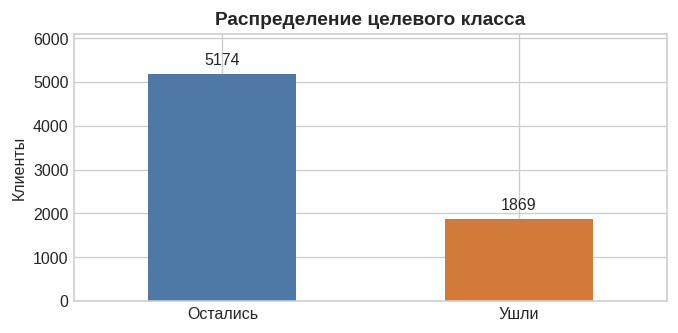

In [4]:
counts = df["Churn"].value_counts().reindex(["No", "Yes"])
balance = pd.DataFrame({"Клиенты": counts, "Доля, %": 100 * counts / counts.sum()})
display(balance.round(2))

ax = counts.rename(index={"No": "Остались", "Yes": "Ушли"}).plot.bar(
    figsize=(6, 3), color=["#4E79A7", "#D17936"], rot=0,
)
ax.set(title="Распределение целевого класса", ylabel="Клиенты", xlabel="")
ax.set_ylim(0, counts.max() * 1.18)
ax.bar_label(ax.containers[0], padding=4)
plt.tight_layout()
plt.show()

Клиенты, которые ушли, составляют примерно четверть выборки. Поэтому используется контрольная модель Dummy, предсказывающая самый частый класс, и несколько метрик. Значение Accuracy отдельно от Recall плохо показывает, насколько модель умеет выявлять отток.

## 3. Разбиение выборки

Первое стратифицированное разбиение выделяет 20% на итоговый тест. На оставшихся 80% классические модели подбираются по стратифицированной 5-кратной кросс-валидации. Для настройки нейросети из этой же обучающей части выделяется 20% на валидацию. После выбора настроек каждая модель обучается на всей 80-процентной части. Итоговые показатели каждой модели вычисляются на одних и тех же клиентах из теста.

In [5]:
y = df["Churn"].map({"No": 0, "Yes": 1})
if y.isna().any():
    raise ValueError("Обнаружено пропущенное или неизвестное значение Churn.")
y = y.astype(int)
X = df.drop(columns=["customerID", "Churn"])
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_cols = [column for column in X.columns if column not in numeric_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED,
)
X_nn_train, X_val, y_nn_train, y_val = train_test_split(
    X_train, y_train, test_size=0.20, stratify=y_train, random_state=SEED,
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

assert y_train.index.intersection(y_test.index).empty
assert y_nn_train.index.intersection(y_val.index).empty

splits = {
    "Обучающая часть до выделения валидации": y_train,
    "Обучение нейросети при подборе": y_nn_train,
    "Валидация нейросети": y_val,
    "Итоговый тест": y_test,
}
display(pd.DataFrame([
    {"Выборка": name, "Клиенты": len(labels), "Churn = 1": labels.sum(),
     "Доля Churn = 1, %": 100 * labels.mean()}
    for name, labels in splits.items()
]).set_index("Выборка").round(2))
print(f"Входные признаки: {X.shape[1]} ({len(numeric_cols)} числовых, {len(categorical_cols)} категориальных).")

Входные признаки: 19 (3 числовых, 16 категориальных).


,Клиенты,Churn = 1,"Доля Churn = 1, %"
Выборка,,,
Обучающая часть до выделения валидации,5634,1495,26.54
Обучение нейросети при подборе,4507,1196,26.54
Валидация нейросети,1127,299,26.53
Итоговый тест,1409,374,26.54


### Преобразование признаков

Категории кодируются через one-hot. Это сохраняет различие между самостоятельными категориями, например `No` и `No internet service`. Бинарный `SeniorCitizen` также обрабатывается как категория. Новый уровень категории при прогнозе обрабатывается без ошибки.

Для большинства моделей и нейросети используется стандартизация числовых признаков. MultinomialNB и ComplementNB требуют неотрицательных входов. Поэтому числовые столбцы для них масштабируются в диапазон [0, 1] и используются как дробные веса признаков. Для BernoulliNB числовые признаки переводятся в 0 и 1 по границе, определённой по медиане обучающей части. Каждое преобразование входит в пайплайн. При кросс-валидации он заново обучается в каждом фолде.

In [6]:
def make_preprocessor(kind="standard"):
    scalers = {
        "standard": StandardScaler(),
        "nonnegative": MinMaxScaler(clip=True),
        "binary": KBinsDiscretizer(
            n_bins=2, encode="ordinal", strategy="quantile",
            quantile_method="averaged_inverted_cdf", subsample=None,
        ),
    }
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", scalers[kind]),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("numbers", numeric, numeric_cols),
        ("categories", categorical, categorical_cols),
    ])

## 4. Методы классификации и метрики

| Модель | Принцип работы |
| :--- | :--- |
| GaussianNB | Использует формулу Байеса с предположением условной независимости признаков. Распределение каждого признака внутри класса приближается нормальным распределением. |
| MultinomialNB | Оценивает веса неотрицательных признаков по их суммарным значениям в каждом классе. |
| ComplementNB | Оценивает веса признаков по наблюдениям из остальных классов. Этот вариант применяют, в частности, при дисбалансе классов. |
| BernoulliNB | Оценивает вероятность присутствия и отсутствия каждого бинарного признака в классе. |
| Decision Tree | Последовательно разбивает пространство признаков, выбирая условия, которые уменьшают неоднородность классов в узлах. |
| LDA | Оценивает средние в каждом классе и общую ковариацию признаков. Граница между классами линейная. |
| SVM | Ищет границу с большим зазором между классами. Линейное ядро задаёт линейную границу, RBF позволяет построить нелинейную. |
| k-NN | Определяет класс по голосам ближайших объектов обучающей выборки. |
| Dummy | Использует частоты классов в обучающей части и предсказывает наиболее частый класс. |

Пусть $TP$ — правильно найденные уходы, $TN$ — правильно найденные оставшиеся клиенты, $FP$ — ложные сигналы об уходе, $FN$ — пропущенные уходы.

| Метрика | Расчёт и смысл |
| :--- | :--- |
| Accuracy | $(TP+TN)/(TP+TN+FP+FN)$ — доля всех верных ответов. |
| Precision | $TP/(TP+FP)$ — доля реально ушедших среди клиентов, предсказанных как ушедшие. |
| Recall | $TP/(TP+FN)$ — доля найденных среди реально ушедших клиентов. |
| F1-score | $2\cdot Precision\cdot Recall/(Precision+Recall)$ — гармоническое среднее Precision и Recall. |
| ROC-AUC | Площадь под кривой зависимости TPR от FPR при переборе порогов. Показывает, как хорошо модель ранжирует положительные примеры выше отрицательных. |

Для ROC-AUC используется непрерывная оценка: вероятность класса 1 или значение `decision_function` для SVM. Остальные метрики вычисляются по предсказанным классам. Если модель ни разу не предсказала положительный класс, Precision принимается равной нулю.

In [7]:
METRICS = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

def evaluate(y_true, labels, scores):
    return {
        "Accuracy": accuracy_score(y_true, labels),
        "Precision": precision_score(y_true, labels, zero_division=0),
        "Recall": recall_score(y_true, labels, zero_division=0),
        "F1": f1_score(y_true, labels, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, scores),
    }

def positive_scores(model, X_part):
    if hasattr(model, "decision_function"):
        return model.decision_function(X_part)
    return model.predict_proba(X_part)[:, 1]

## 5. Настройка гиперпараметров

`GridSearchCV` перебирает заданные комбинации. Основной критерий выбора — средний ROC-AUC по пяти фолдам. F1 по тем же фолдам используется как дополнительная характеристика предсказанных классов. Для каждого варианта сохранены среднее и стандартное отклонение ROC-AUC. Базовая настройка каждой модели включена в соответствующую сетку.

In [8]:
def parameter_grid(**parameters):
    return {f"clf__{name}": values for name, values in parameters.items()}

specs = {
    "GaussianNB": (
        GaussianNB(), "standard",
        parameter_grid(var_smoothing=[1e-12, 1e-9, 1e-6, 1e-4, 1e-2, 0.1, 0.5]),
        {"var_smoothing": 1e-9},
    ),
    "MultinomialNB": (
        MultinomialNB(), "nonnegative",
        parameter_grid(alpha=[0.01, 0.1, 1.0, 10.0, 50.0], fit_prior=[True, False]),
        {"alpha": 1.0, "fit_prior": True},
    ),
    "ComplementNB": (
        ComplementNB(), "nonnegative",
        parameter_grid(alpha=[0.01, 0.1, 1.0, 10.0, 50.0], norm=[False, True]),
        {"alpha": 1.0, "norm": False},
    ),
    "BernoulliNB": (
        BernoulliNB(binarize=None), "binary",
        parameter_grid(alpha=[0.01, 0.1, 1.0, 10.0, 50.0], fit_prior=[True, False]),
        {"alpha": 1.0, "fit_prior": True},
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED), "standard",
        [
            parameter_grid(max_depth=[None], min_samples_leaf=[1]),
            parameter_grid(max_depth=[3, 5, 8, 12], min_samples_leaf=[1, 15, 40]),
        ],
        {"max_depth": None, "min_samples_leaf": 1},
    ),
    "LDA": (
        LinearDiscriminantAnalysis(), "standard",
        [
            parameter_grid(solver=["svd"]),
            parameter_grid(solver=["lsqr"], shrinkage=["auto", 0.05, 0.20, 0.50, 0.90]),
        ],
        {"solver": "svd"},
    ),
    "SVM": (
        SVC(random_state=SEED), "standard",
        [
            parameter_grid(kernel=["linear"], C=[0.1, 1.0, 5.0], class_weight=[None, "balanced"]),
            parameter_grid(kernel=["rbf"], C=[0.1, 1.0, 5.0], gamma=["scale", 0.01, 0.1],
                           class_weight=[None, "balanced"]),
        ],
        {"kernel": "rbf", "C": 1.0, "gamma": "scale", "class_weight": None},
    ),
    "k-NN": (
        KNeighborsClassifier(), "standard",
        parameter_grid(n_neighbors=[5, 11, 21, 41, 81], weights=["uniform", "distance"], p=[1, 2]),
        {"n_neighbors": 5, "weights": "uniform", "p": 2},
    ),
}

def short_params(params):
    return {key.removeprefix("clf__"): value for key, value in params.items()}

searches = {}
summaries = []
experiments = []

with threadpool_limits(limits=2):
    for name, (estimator, kind, grid, baseline) in specs.items():
        pipeline = Pipeline([("preprocess", make_preprocessor(kind)), ("clf", estimator)])
        search = GridSearchCV(
            pipeline, grid, scoring={"auc": "roc_auc", "f1": "f1"}, refit="auc",
            cv=cv, n_jobs=1, error_score="raise",
        )
        search.fit(X_train, y_train)
        searches[name] = search

        rows = pd.DataFrame(search.cv_results_)[[
            "params", "mean_test_auc", "std_test_auc", "mean_test_f1"
        ]].copy()
        rows["params"] = rows["params"].map(short_params)
        baseline_row = rows.loc[rows["params"].map(lambda params: params == baseline)].iloc[0]
        best_row = rows.iloc[search.best_index_]
        summaries.append({
            "Модель": name, "Вариантов": len(rows), "AUC базы": baseline_row["mean_test_auc"],
            "AUC после поиска": best_row["mean_test_auc"], "σ AUC": best_row["std_test_auc"],
            "Δ AUC": best_row["mean_test_auc"] - baseline_row["mean_test_auc"],
            "Лучшие параметры": best_row["params"],
        })
        rows.insert(0, "Модель", name)
        experiments.append(rows)

cv_summary = pd.DataFrame(summaries).set_index("Модель")
cv_trials = pd.concat(experiments, ignore_index=True)
print(f"Проверено комбинаций: {len(cv_trials)}. Обучений в фолдах: {len(cv_trials) * cv.n_splits}.")
display(cv_summary.round(4))

Проверено комбинаций: 100. Обучений в фолдах: 500.


,Вариантов,AUC базы,AUC после поиска,σ AUC,Δ AUC,Лучшие параметры
Модель,,,,,,
GaussianNB,7,0.8199,0.8274,0.0106,0.0075,{'var_smoothing': 0.5}
MultinomialNB,10,0.8206,0.8206,0.0114,0.0000,"{'alpha': 0.1, 'fit_prior': True}"
ComplementNB,10,0.8206,0.8206,0.0114,0.0000,"{'alpha': 0.1, 'norm': False}"
BernoulliNB,10,0.8221,0.8224,0.0108,0.0003,"{'alpha': 50.0, 'fit_prior': True}"
Decision Tree,13,0.6559,0.8293,0.0107,0.1734,"{'max_depth': 5, 'min_samples_leaf': 40}"
LDA,6,0.8390,0.8413,0.0107,0.0023,"{'shrinkage': 0.5, 'solver': 'lsqr'}"
SVM,24,0.7989,0.8423,0.0102,0.0434,"{'C': 1.0, 'class_weight': 'balanced', 'gamma'..."
k-NN,20,0.7825,0.8378,0.0103,0.0553,"{'n_neighbors': 81, 'p': 2, 'weights': 'uniform'}"


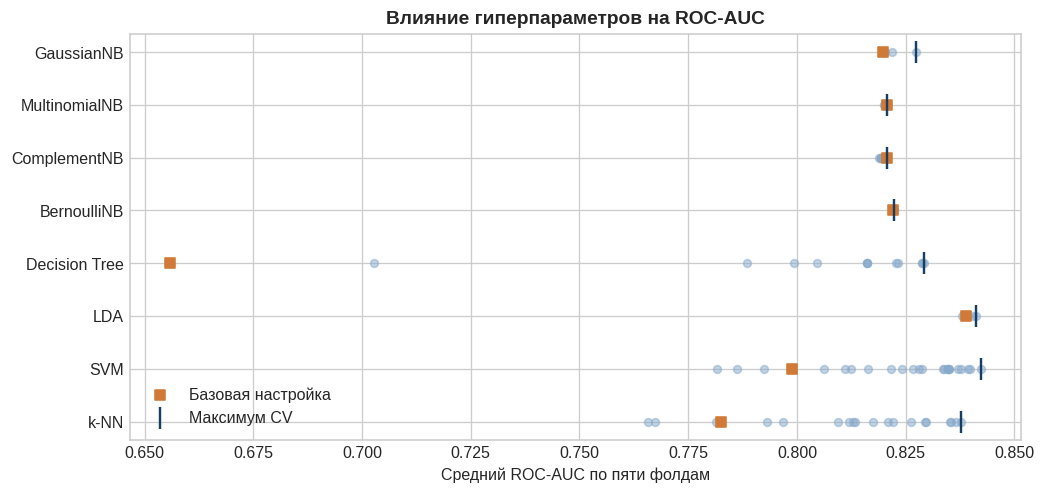

**GaussianNB**

,Параметры,Средний AUC,σ AUC,Средний F1
0,{'var_smoothing': 0.5},0.8274,0.0106,0.5982
1,{'var_smoothing': 0.1},0.8218,0.0117,0.5958
2,{'var_smoothing': 0.01},0.8202,0.0117,0.5988
3,{'var_smoothing': 0.0001},0.8199,0.0117,0.5985
4,{'var_smoothing': 1e-12},0.8199,0.0117,0.5985
5,{'var_smoothing': 1e-09},0.8199,0.0117,0.5985
6,{'var_smoothing': 1e-06},0.8199,0.0117,0.5985


**MultinomialNB**

,Параметры,Средний AUC,σ AUC,Средний F1
0,"{'alpha': 0.1, 'fit_prior': True}",0.8206,0.0114,0.6087
1,"{'alpha': 0.1, 'fit_prior': False}",0.8206,0.0114,0.5960
2,"{'alpha': 0.01, 'fit_prior': True}",0.8206,0.0114,0.6087
3,"{'alpha': 0.01, 'fit_prior': False}",0.8206,0.0114,0.5962
4,"{'alpha': 1.0, 'fit_prior': True}",0.8206,0.0114,0.6082
5,"{'alpha': 1.0, 'fit_prior': False}",0.8206,0.0114,0.5960
6,"{'alpha': 10.0, 'fit_prior': True}",0.8205,0.0114,0.6071
7,"{'alpha': 10.0, 'fit_prior': False}",0.8205,0.0114,0.5958
8,"{'alpha': 50.0, 'fit_prior': True}",0.8201,0.0111,0.6049
9,"{'alpha': 50.0, 'fit_prior': False}",0.8201,0.0111,0.5907


**ComplementNB**

,Параметры,Средний AUC,σ AUC,Средний F1
0,"{'alpha': 0.1, 'norm': False}",0.8206,0.0114,0.5960
1,"{'alpha': 0.01, 'norm': False}",0.8206,0.0114,0.5962
2,"{'alpha': 1.0, 'norm': False}",0.8206,0.0114,0.5960
3,"{'alpha': 10.0, 'norm': False}",0.8205,0.0114,0.5958
4,"{'alpha': 50.0, 'norm': False}",0.8201,0.0111,0.5907
5,"{'alpha': 0.01, 'norm': True}",0.8194,0.0113,0.5006
6,"{'alpha': 0.1, 'norm': True}",0.8194,0.0113,0.5007
7,"{'alpha': 1.0, 'norm': True}",0.8194,0.0113,0.5008
8,"{'alpha': 10.0, 'norm': True}",0.8193,0.0113,0.5029
9,"{'alpha': 50.0, 'norm': True}",0.8190,0.0110,0.5115


... (6 outputs left out)

**SVM**

,Параметры,Средний AUC,σ AUC,Средний F1
0,"{'C': 1.0, 'class_weight': 'balanced', 'gamma'...",0.8423,0.0102,0.6040
1,"{'C': 0.1, 'class_weight': 'balanced', 'gamma'...",0.8398,0.0101,0.6205
2,"{'C': 5.0, 'class_weight': 'balanced', 'gamma'...",0.8394,0.0101,0.6068
3,"{'C': 0.1, 'class_weight': None, 'gamma': 0.01...",0.8377,0.0121,0.5163
4,"{'C': 0.1, 'class_weight': 'balanced', 'gamma'...",0.8369,0.0114,0.6215
5,"{'C': 0.1, 'class_weight': 'balanced', 'gamma'...",0.8351,0.0113,0.6215
6,"{'C': 1.0, 'class_weight': None, 'gamma': 0.01...",0.8350,0.0140,0.5635
7,"{'C': 1.0, 'class_weight': 'balanced', 'kernel...",0.8346,0.0100,0.5983
8,"{'C': 0.1, 'class_weight': None, 'kernel': 'li...",0.8345,0.0131,0.5846
9,"{'C': 5.0, 'class_weight': None, 'kernel': 'li...",0.8339,0.0133,0.5845


**k-NN**

,Параметры,Средний AUC,σ AUC,Средний F1
0,"{'n_neighbors': 81, 'p': 2, 'weights': 'uniform'}",0.8378,0.0103,0.5955
1,"{'n_neighbors': 81, 'p': 1, 'weights': 'uniform'}",0.8366,0.0094,0.5972
2,"{'n_neighbors': 41, 'p': 2, 'weights': 'uniform'}",0.8354,0.0096,0.6021
3,"{'n_neighbors': 41, 'p': 1, 'weights': 'uniform'}",0.8353,0.0088,0.6058
4,"{'n_neighbors': 21, 'p': 2, 'weights': 'uniform'}",0.8297,0.0090,0.5909
5,"{'n_neighbors': 21, 'p': 1, 'weights': 'uniform'}",0.8296,0.0080,0.5926
6,"{'n_neighbors': 81, 'p': 2, 'weights': 'distan...",0.8263,0.0108,0.5843
7,"{'n_neighbors': 81, 'p': 1, 'weights': 'distan...",0.8220,0.0107,0.5799
8,"{'n_neighbors': 41, 'p': 2, 'weights': 'distan...",0.8208,0.0118,0.5808
9,"{'n_neighbors': 41, 'p': 1, 'weights': 'distan...",0.8174,0.0122,0.5807


In [9]:
# Баллы по всем комбинациям и диапазон AUC для каждого алгоритма.
cv_span = cv_trials.groupby("Модель", sort=False)["mean_test_auc"].agg(["min", "max"])
fig, ax = plt.subplots(figsize=(9.2, 4.4))
for y_pos, name in enumerate(cv_summary.index):
    scores = cv_trials.loc[cv_trials["Модель"].eq(name), "mean_test_auc"].to_numpy()
    ax.scatter(scores, np.full(scores.shape, y_pos), color="#86A9CA", alpha=0.50, s=24)
    ax.scatter(cv_summary.loc[name, "AUC базы"], y_pos, marker="s", color="#D17936",
               label="Базовая настройка" if y_pos == 0 else None, zorder=4)
    ax.scatter(cv_summary.loc[name, "AUC после поиска"], y_pos, marker="|", s=200, color="#163D63",
               label="Максимум CV" if y_pos == 0 else None, zorder=5)
ax.set(yticks=range(len(cv_summary)), yticklabels=cv_summary.index,
       xlabel="Средний ROC-AUC по пяти фолдам", title="Влияние гиперпараметров на ROC-AUC")
ax.invert_yaxis()
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

columns = {"params": "Параметры", "mean_test_auc": "Средний AUC",
           "std_test_auc": "σ AUC", "mean_test_f1": "Средний F1"}
for name in cv_summary.index:
    rows = cv_trials.loc[cv_trials["Модель"].eq(name), list(columns)].sort_values(
        "mean_test_auc", ascending=False, kind="stable"
    )
    display(Markdown(f"**{name}**"))
    display(rows.rename(columns=columns).reset_index(drop=True).round(4))

In [10]:
fmt = lambda value: f"{value:.4f}".replace(".", ",")
descriptions = {
    "GaussianNB": "Проверялось сглаживание оценок дисперсии.",
    "MultinomialNB": "Менялись сглаживание и способ учёта априорных частот классов.",
    "ComplementNB": "Менялись сглаживание и нормировка весов.",
    "BernoulliNB": "Менялись сглаживание бинарных вероятностей и учёт частот классов.",
    "Decision Tree": "Ограничивались глубина дерева и минимальное число объектов в листе.",
    "LDA": "Сравнивались SVD и решение методом наименьших квадратов с регуляризацией ковариации.",
    "SVM": "Сравнивались ядра, значения C, ширина RBF и веса классов.",
    "k-NN": "Менялись число соседей, способ голосования и метрика расстояния.",
}
lines = []
for name, row in cv_summary.iterrows():
    delta = row["Δ AUC"]
    change = ("базовая настройка уже достигла максимума" if np.isclose(delta, 0)
              else f"максимум выше базы на {fmt(delta)}")
    if 0 < delta < 0.00005:
        change = "разница между максимумом и базой меньше 0,00005"
    lines.append(
        f"- **{name}.** {descriptions[name]} Диапазон AUC "
        f"{fmt(cv_span.loc[name, 'min'])}–{fmt(cv_span.loc[name, 'max'])}. Сравнение с базой показывает, что {change}."
    )

leader_cv = cv_summary["AUC после поиска"].idxmax()
largest_gain = cv_summary["Δ AUC"].idxmax()
display(Markdown(
    "### Интерпретация экспериментов\n\n" + "\n".join(lines)
    + f"\n\nМаксимальный прирост относительно базовой настройки показал **{largest_gain}**. "
      f"По среднему CV ROC-AUC лидировал **{leader_cv}**. "
      "Небольшие различия следует рассматривать вместе с разбросом по фолдам."
))

### Интерпретация экспериментов

- **GaussianNB.** Проверялось сглаживание оценок дисперсии. Диапазон AUC 0,8199–0,8274. Сравнение с базой показывает, что максимум выше базы на 0,0075.
- **MultinomialNB.** Менялись сглаживание и способ учёта априорных частот классов. Диапазон AUC 0,8201–0,8206. Сравнение с базой показывает, что разница между максимумом и базой меньше 0,00005.
- **ComplementNB.** Менялись сглаживание и нормировка весов. Диапазон AUC 0,8190–0,8206. Сравнение с базой показывает, что разница между максимумом и базой меньше 0,00005.
- **BernoulliNB.** Менялись сглаживание бинарных вероятностей и учёт частот классов. Диапазон AUC 0,8220–0,8224. Сравнение с базой показывает, что максимум выше базы на 0,0003.
- **Decision Tree.** Ограничивались глубина дерева и минимальное число объектов в листе. Диапазон AUC 0,6559–0,8293. Сравнение с базой показывает, что максимум выше базы на 0,1734.
- **LDA.** Сравнивались SVD и решение методом наименьших квадратов с регуляризацией ковариации. Диапазон AUC 0,8380–0,8413. Сравнение с базой показывает, что максимум выше базы на 0,0023.
- **SVM.** Сравнивались ядра, значения C, ширина RBF и веса классов. Диапазон AUC 0,7815–0,8423. Сравнение с базой показывает, что максимум выше базы на 0,0434.
- **k-NN.** Менялись число соседей, способ голосования и метрика расстояния. Диапазон AUC 0,7657–0,8378. Сравнение с базой показывает, что максимум выше базы на 0,0553.

Максимальный прирост относительно базовой настройки показал **Decision Tree**. По среднему CV ROC-AUC лидировал **SVM**. Небольшие различия следует рассматривать вместе с разбросом по фолдам.

## 6. Нейронная сеть на TensorFlow

Базовая архитектура — многослойный персептрон с двумя скрытыми слоями `Dense(64)` и `Dense(32)` с активацией ReLU. Выходной слой `Dense(1, activation="sigmoid")` выдаёт вероятность оттока. Используется бинарная кросс-энтропия и оптимизатор Adam с шагом 0,001. Accuracy измеряется при пороге вероятности 0,5.

В каждом эксперименте меняется один фактор относительно базовой конфигурации (30 эпох, батч из 64 объектов, два слоя, ReLU). При сравнении глубины сеть сохраняет первые слои базовой конфигурации и добавляет или удаляет последний скрытый слой. При добавлении или удалении слоя число обучаемых весов также меняется. Критерий выбора — точный ROC-AUC на валидации после последней эпохи, рассчитанный по всем прогнозам. Keras отдельно приближённо рассчитывает AUC по сетке порогов для мониторинга по эпохам.

In [11]:
nn_preprocessor = make_preprocessor()
nn_X_train = nn_preprocessor.fit_transform(X_nn_train).astype("float32")
nn_X_val = nn_preprocessor.transform(X_val).astype("float32")

nn_base = {"layers": (64, 32), "activation": "relu", "batch_size": 64, "epochs": 30}
nn_configs = {
    "baseline": ("Базовый вариант", nn_base),
    "epochs_12": ("Эпохи", {**nn_base, "epochs": 12}),
    "epochs_60": ("Эпохи", {**nn_base, "epochs": 60}),
    "batch_32": ("Размер батча", {**nn_base, "batch_size": 32}),
    "batch_128": ("Размер батча", {**nn_base, "batch_size": 128}),
    "one_layer": ("Глубина", {**nn_base, "layers": (64,)}),
    "three_layers": ("Глубина", {**nn_base, "layers": (64, 32, 16)}),
    "narrow": ("Ширина", {**nn_base, "layers": (32, 16)}),
    "wide": ("Ширина", {**nn_base, "layers": (128, 64)}),
    "tanh": ("Активация", {**nn_base, "activation": "tanh"}),
    "elu": ("Активация", {**nn_base, "activation": "elu"}),
}
run_stamp = datetime.now().strftime("%Y%m%d-%H%M%S-%f")
log_root = Path("logs") / "telco_churn" / run_stamp

def make_dataset(features, targets, batch_size, shuffle=False):
    features = np.asarray(features, dtype="float32")
    targets = np.asarray(targets, dtype="float32").reshape(-1, 1)
    dataset = tf.data.Dataset.from_tensor_slices((features, targets))
    if shuffle:
        dataset = dataset.shuffle(len(features), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return dataset.batch(batch_size).with_options(options).prefetch(1)

def make_network(n_features, config):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(n_features,)),
        *(tf.keras.layers.Dense(width, activation=config["activation"])
          for width in config["layers"]),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"), tf.keras.metrics.AUC(name="auc")],
    )
    return model

def fit_network(features, targets, config, validation=None, log_dir=None):
    model = make_network(features.shape[1], config)
    batch_size = config["batch_size"]
    train_data = make_dataset(features, targets, batch_size, shuffle=True)
    val_data = None if validation is None else make_dataset(*validation, batch_size)
    callbacks = []
    if log_dir is not None:
        callbacks.append(tf.keras.callbacks.TensorBoard(
            log_dir=str(log_dir), update_freq="epoch", profile_batch=0,
        ))
    history = model.fit(
        train_data, validation_data=val_data, epochs=config["epochs"],
        callbacks=callbacks, verbose=0, shuffle=False,
    )
    return model, pd.DataFrame(history.history)

def predict_network(model, features):
    return model(features, training=False).numpy().ravel()

In [12]:
nn_histories = {}
nn_observations = []

for run, (factor, config) in nn_configs.items():
    model, history = fit_network(
        nn_X_train, y_nn_train, config, validation=(nn_X_val, y_val), log_dir=log_root / run,
    )
    nn_histories[run] = history
    val_scores = predict_network(model, nn_X_val)
    nn_observations.append({
        "Эксперимент": run, "Фактор": factor, "Эпохи": config["epochs"],
        "Батч": config["batch_size"], "Слои": config["layers"],
        "Активация": config["activation"], "Весов и смещений": model.count_params(),
        "Val loss": history["val_loss"].iloc[-1],
        "Val Accuracy": history["val_accuracy"].iloc[-1],
        "Val F1": f1_score(y_val, val_scores >= 0.5, zero_division=0),
        "Val ROC-AUC": roc_auc_score(y_val, val_scores),
    })

nn_results = pd.DataFrame(nn_observations).set_index("Эксперимент")
nn_results["Δ AUC к базе"] = nn_results["Val ROC-AUC"] - nn_results.loc["baseline", "Val ROC-AUC"]
nn_best_run = nn_results["Val ROC-AUC"].idxmax()
print(f"Вход нейросети после кодирования: {nn_X_train.shape[1]} признаков.")
display(nn_results.round(4))

Вход нейросети после кодирования: 46 признаков.


,Фактор,Эпохи,Батч,Слои,Активация,Весов и смещений,Val loss,Val Accuracy,Val F1,Val ROC-AUC,Δ AUC к базе
Эксперимент,,,,,,,,,,,
baseline,Базовый вариант,30,64,"(64, 32)",relu,5121,0.4375,0.8004,0.6004,0.8325,0.0000
epochs_12,Эпохи,12,64,"(64, 32)",relu,5121,0.4191,0.8146,0.5812,0.8438,0.0114
epochs_60,Эпохи,60,64,"(64, 32)",relu,5121,0.4899,0.7950,0.5698,0.8160,-0.0165
batch_32,Размер батча,30,32,"(64, 32)",relu,5121,0.4493,0.7897,0.6030,0.8310,-0.0015
batch_128,Размер батча,30,128,"(64, 32)",relu,5121,0.4234,0.8101,0.6095,0.8421,0.0097
one_layer,Глубина,30,64,"(64,)",relu,3073,0.4162,0.8154,0.6204,0.8466,0.0141
three_layers,Глубина,30,64,"(64, 32, 16)",relu,5633,0.4720,0.7693,0.5608,0.8147,-0.0178
narrow,Ширина,30,64,"(32, 16)",relu,2049,0.4221,0.8146,0.6108,0.8409,0.0084
wide,Ширина,30,64,"(128, 64)",relu,14337,0.4692,0.7711,0.5757,0.8196,-0.0129


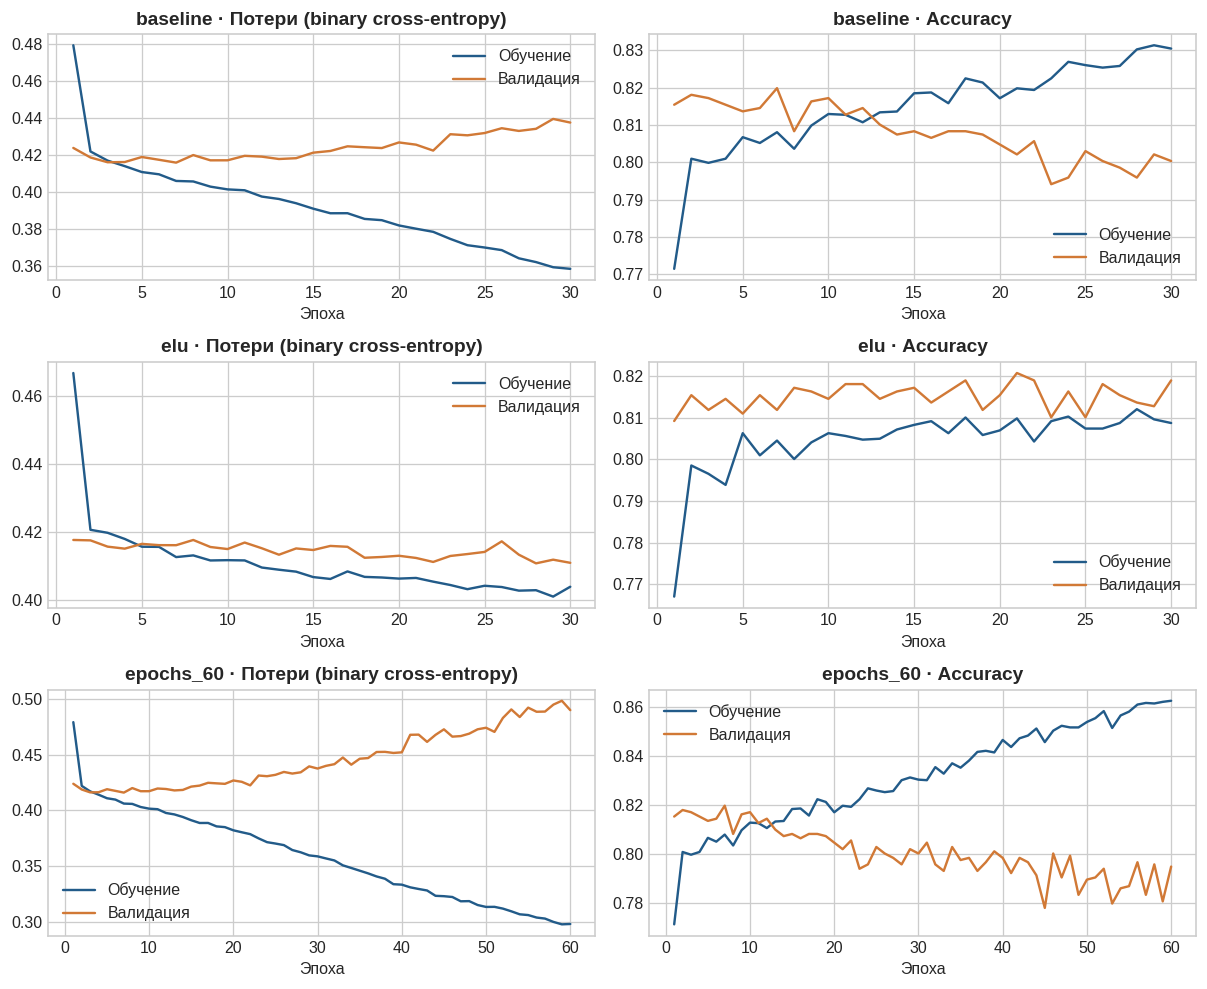

Настройка **elu** показала наибольший валидационный ROC-AUC, **0,8508**. У базовой сети ROC-AUC равен 0,8325. Изменения ROC-AUC относительно базы приведены ниже.

- **Эпохи.** `epochs_12` (+0.0114), `epochs_60` (-0.0165).
- **Размер батча.** `batch_32` (-0.0015), `batch_128` (+0.0097).
- **Глубина.** `one_layer` (+0.0141), `three_layers` (-0.0178).
- **Ширина.** `narrow` (+0.0084), `wide` (-0.0129).
- **Активация.** `tanh` (+0.0149), `elu` (+0.0183).

В 60-эпоховом запуске минимальная валидационная потеря 0,4159 наблюдалась на эпохе 7. На последней эпохе потери обучения и валидации составили соответственно 0,2978 и 0,4899. Рост валидационной потери после минимума при меньшей обучающей потере указывает на переобучение в этом запуске.

In [13]:
metrics_to_plot = [
    ("loss", "Потери (binary cross-entropy)"),
    ("accuracy", "Accuracy"),
]
selected_runs = list(dict.fromkeys(["baseline", nn_best_run, "epochs_60"]))
fig, axes = plt.subplots(len(selected_runs), 2, figsize=(10.6, 2.9 * len(selected_runs)), squeeze=False)

for row, run in enumerate(selected_runs):
    history = nn_histories[run]
    epochs = np.arange(1, len(history) + 1)
    for ax, (metric, label) in zip(axes[row], metrics_to_plot):
        ax.plot(epochs, history[metric], color="#225B89", label="Обучение")
        ax.plot(epochs, history[f"val_{metric}"], color="#D17936", label="Валидация")
        ax.set(title=f"{run} · {label}", xlabel="Эпоха")
        ax.legend(loc="best")
fig.tight_layout()
plt.show()

base_auc = nn_results.loc["baseline", "Val ROC-AUC"]
best_auc = nn_results.loc[nn_best_run, "Val ROC-AUC"]
lines = []
for factor, group in nn_results.drop(index="baseline").groupby("Фактор", sort=False):
    effect = ", ".join(f"`{run}` ({delta:+.4f})" for run, delta in group["Δ AUC к базе"].items())
    lines.append(f"- **{factor}.** {effect}.")
long_history = nn_histories["epochs_60"]
min_val_epoch = int(long_history["val_loss"].idxmin()) + 1
train_end = long_history["loss"].iloc[-1]
val_end = long_history["val_loss"].iloc[-1]
val_min = long_history["val_loss"].min()
display(Markdown(
    f"Настройка **{nn_best_run}** показала наибольший валидационный ROC-AUC, "
    f"**{fmt(best_auc)}**. У базовой сети ROC-AUC равен {fmt(base_auc)}. "
    "Изменения ROC-AUC относительно базы приведены ниже.\n\n"
    + "\n".join(lines)
    + f"\n\nВ 60-эпоховом запуске минимальная валидационная потеря "
      f"{fmt(val_min)} наблюдалась на эпохе {min_val_epoch}. "
      f"На последней эпохе потери обучения и валидации составили соответственно "
      f"{fmt(train_end)} и {fmt(val_end)}. "
    + ("Рост валидационной потери после минимума при меньшей обучающей потере "
       "указывает на переобучение в этом запуске."
       if min_val_epoch < len(long_history) and val_end > train_end else
       "Положение минимума и разрыв кривых помогают судить о выборе числа эпох.")
))

### Мониторинг обучения в TensorBoard

Callback `tf.keras.callbacks.TensorBoard` записывает события каждой эпохи в отдельные каталоги `train` и `validation` для каждого эксперимента. На вкладке **Scalars** серии `epoch_loss` и `epoch_accuracy` показывают потери и точность обеих выборок. Можно выбрать нужный запуск и поменять сглаживание. Документация по запуску доступна на странице [TensorBoard in Notebooks](https://www.tensorflow.org/tensorboard/tensorboard_in_notebooks).

Следующая ячейка считывает исходные журналы TensorBoard и проверяет, что в них записаны требуемые показатели. В выводе показаны записи последней эпохи базовой и выбранной конфигураций.

In [14]:
def read_epoch_metric(run, split, tag):
    directory = log_root / run / split
    accumulator = EventAccumulator(str(directory), size_guidance={"tensors": 0, "scalars": 0})
    accumulator.Reload()
    tags = accumulator.Tags()
    if tag in tags["tensors"]:
        return {event.step: float(tensor_util.make_ndarray(event.tensor_proto))
                for event in accumulator.Tensors(tag)}
    if tag in tags["scalars"]:
        return {event.step: float(event.value) for event in accumulator.Scalars(tag)}
    raise ValueError(f"В {directory} отсутствует журнал {tag}.")

log_samples = []
for run, (_, config) in nn_configs.items():
    for split in ["train", "validation"]:
        losses = read_epoch_metric(run, split, "epoch_loss")
        accuracies = read_epoch_metric(run, split, "epoch_accuracy")
        assert len(losses) == len(accuracies) == config["epochs"]
        assert losses.keys() == accuracies.keys()
        if run in {"baseline", nn_best_run}:
            last_step = max(losses)
            log_samples.append({
                "Запуск": run, "Выборка": split, "Эпоха": last_step + 1,
                "Loss": losses[last_step], "Accuracy": accuracies[last_step],
            })

print(f"Проверены журналы всех {len(nn_configs)} запусков TensorBoard.")
display(pd.DataFrame(log_samples).round(4))
print(f"В терминале: tensorboard --logdir {log_root.as_posix()}")

Проверены журналы всех 11 запусков TensorBoard.
В терминале: tensorboard --logdir logs/telco_churn/20261118-143459-014344


,Запуск,Выборка,Эпоха,Loss,Accuracy
0,baseline,train,30,0.3586,0.8305
1,baseline,validation,30,0.4375,0.8004
2,elu,train,30,0.4039,0.8087
3,elu,validation,30,0.4109,0.8190


Чтобы открыть интерактивный TensorBoard в Jupyter, выполните две закомментированные строки ниже после обучения. Его также можно открыть из терминала командой из вывода предыдущей ячейки.

In [15]:
# %load_ext tensorboard
# %tensorboard --logdir $log_root

### Графики из журналов TensorBoard

Ниже показаны потери и точность выбранной конфигурации по реальным событиям TensorBoard. Графики сохранены в отчёте и видны без запуска интерактивной панели.

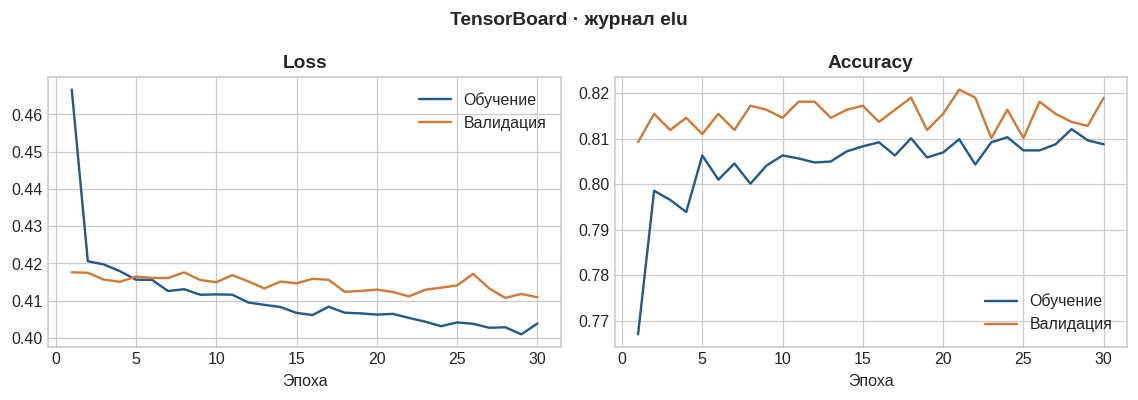

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (tag, title) in zip(axes, [("epoch_loss", "Loss"), ("epoch_accuracy", "Accuracy")]):
    for split, label, color in [
        ("train", "Обучение", "#225B89"),
        ("validation", "Валидация", "#D17936"),
    ]:
        series = read_epoch_metric(nn_best_run, split, tag)
        epochs = sorted(series)
        ax.plot([step + 1 for step in epochs], [series[step] for step in epochs],
                label=label, color=color)
    ax.set(title=title, xlabel="Эпоха")
    ax.legend()
fig.suptitle(f"TensorBoard · журнал {nn_best_run}", fontweight="bold")
fig.tight_layout()
plt.show()

## 7. Сравнительный анализ

Классические модели заново обучены на всей обучающей выборке через `refit="auc"`. Нейросеть с выбранной архитектурой обучается заново на той же полной обучающей выборке с тем же числом эпох. Предобработка для финальной сети вновь оценивается по обучающей части. Для тестовых метрик, зависящих от порога, у классических моделей используются классы из `predict`, а у нейросети — порог 0,5.

In [17]:
final_preprocessor = make_preprocessor()
train_features = final_preprocessor.fit_transform(X_train).astype("float32")
test_features = final_preprocessor.transform(X_test).astype("float32")
_, final_nn_config = nn_configs[nn_best_run]
final_nn, _ = fit_network(train_features, y_train, final_nn_config)

dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
fitted_classical = {"Dummy": dummy, **{name: search.best_estimator_ for name, search in searches.items()}}
predictions = {}
scores = {}
with threadpool_limits(limits=2):
    for name, model in fitted_classical.items():
        predictions[name] = model.predict(X_test)
        scores[name] = positive_scores(model, X_test)

nn_name = "TensorFlow MLP"
scores[nn_name] = predict_network(final_nn, test_features)
predictions[nn_name] = (scores[nn_name] >= 0.5).astype(int)

comparison = pd.DataFrame({
    name: evaluate(y_test, predictions[name], scores[name]) for name in scores
}).T.sort_values("ROC-AUC", ascending=False)
comparison.index.name = "Модель"
display(comparison.style.format(precision=4).highlight_max(axis=0, color="#D8F1DE"))
print(f"Единая тестовая выборка: {len(y_test)} клиентов, из них ушли {y_test.sum()}.")

Единая тестовая выборка: 1409 клиентов, из них ушли 374.


,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
TensorFlow MLP,0.7977,0.6344,0.5615,0.5957,0.8441
LDA,0.7786,0.5714,0.6631,0.6139,0.8347
SVM,0.7040,0.4673,0.8209,0.5955,0.8334
k-NN,0.7793,0.5858,0.5749,0.5803,0.8307
Decision Tree,0.7956,0.6405,0.5241,0.5765,0.8272
GaussianNB,0.6934,0.4572,0.8289,0.5894,0.8182
BernoulliNB,0.7154,0.4784,0.7995,0.5986,0.8098
MultinomialNB,0.7090,0.4716,0.7995,0.5933,0.8066
ComplementNB,0.6785,0.4444,0.8449,0.5825,0.8066


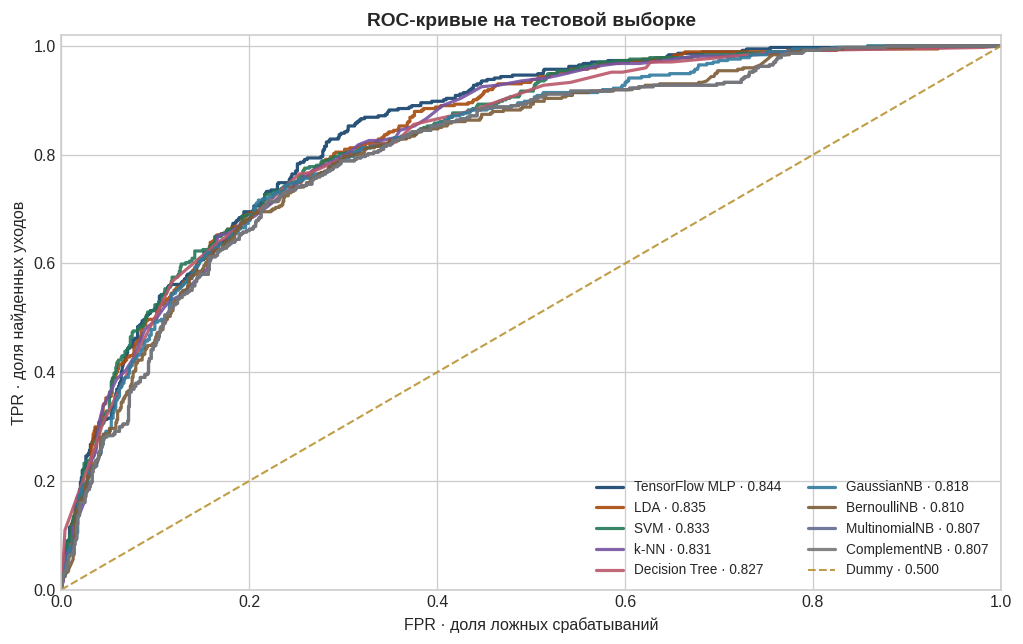

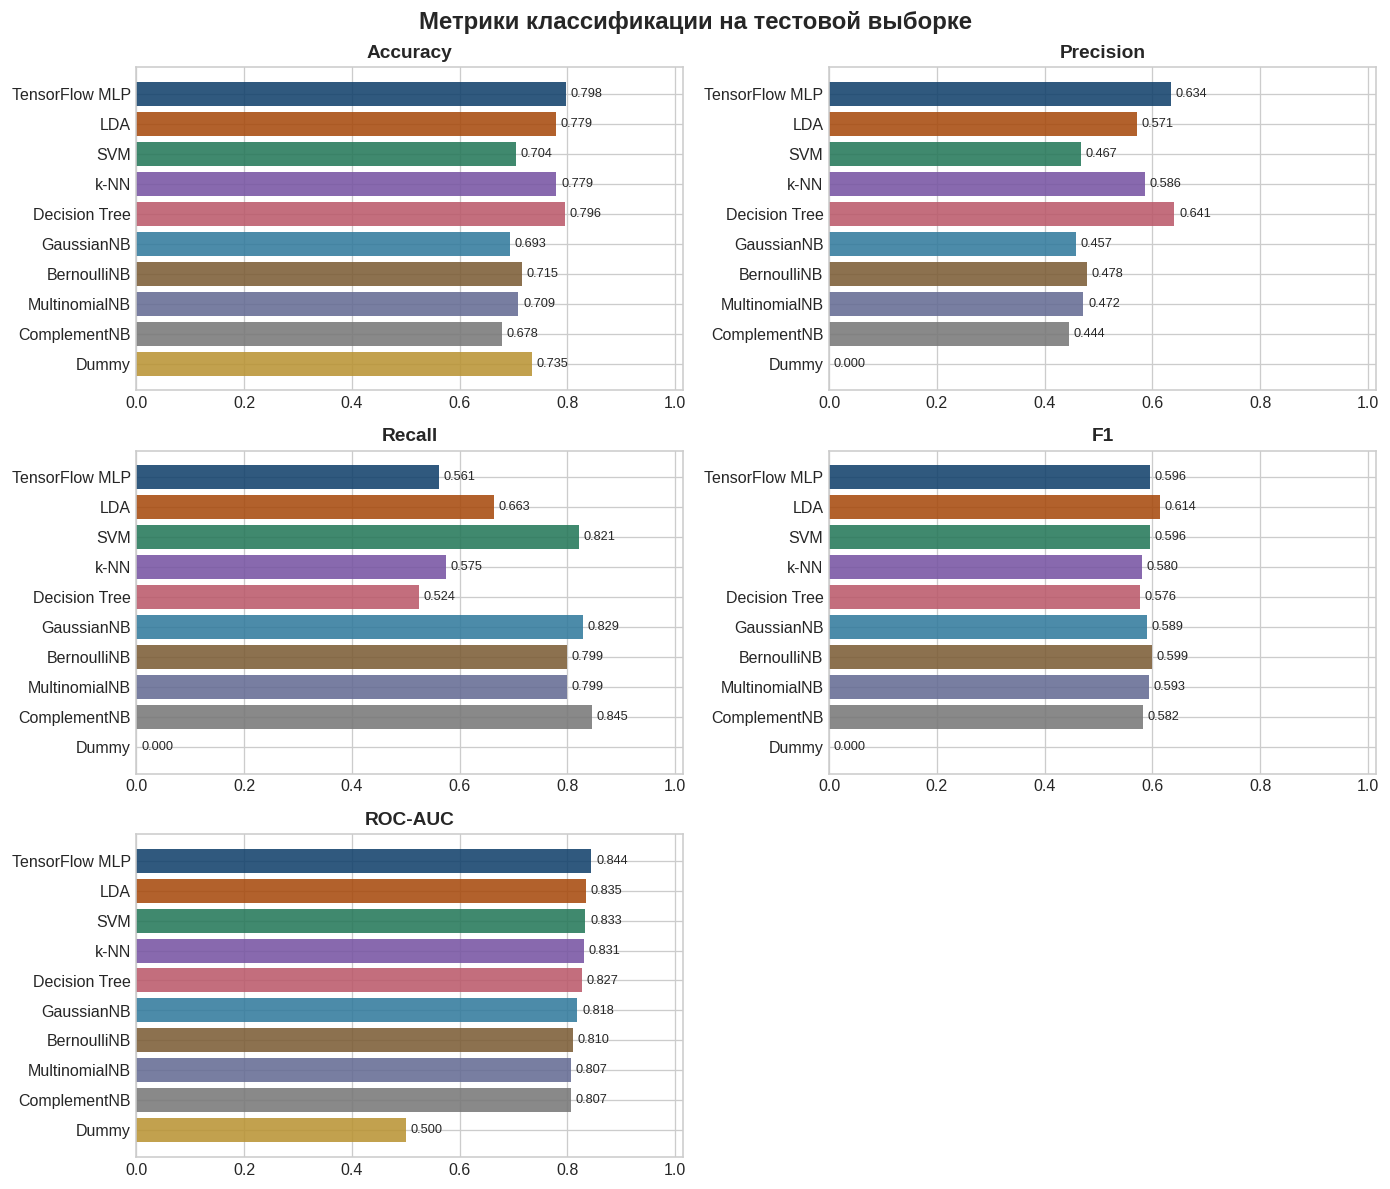

In [18]:
palette = dict(zip(
    comparison.index,
    ["#11406B", "#A7490C", "#247758", "#7653A2", "#BA586A",
     "#317A9C", "#7B5C35", "#646B93", "#777777", "#B99333"],
))
fig, ax = plt.subplots(figsize=(9, 5.7))
for name, row in comparison.iterrows():
    fpr, tpr, _ = roc_curve(y_test, scores[name])
    ax.plot(
        fpr, tpr, color=palette[name], lw=2 if name != "Dummy" else 1.3,
        ls="--" if name == "Dummy" else "-", alpha=0.9,
        label=f"{name} · {row['ROC-AUC']:.3f}",
    )
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="FPR · доля ложных срабатываний",
       ylabel="TPR · доля найденных уходов", title="ROC-кривые на тестовой выборке")
ax.legend(loc="lower right", ncol=2, fontsize=8.5)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 2, figsize=(12.2, 10.5), sharex=True)
for ax, metric in zip(axes.flat, METRICS):
    metric_values = comparison[metric].iloc[::-1]
    bars = ax.barh(
        metric_values.index, metric_values,
        color=[palette[name] for name in metric_values.index], alpha=0.87,
    )
    ax.bar_label(bars, labels=[f"{value:.3f}" for value in metric_values], padding=3, fontsize=8)
    ax.set(title=metric, xlim=(0, 1.015), xticks=np.linspace(0, 1, 6))
    ax.tick_params(axis="x", labelbottom=True)
axes.flat[-1].set_axis_off()
fig.suptitle("Метрики классификации на тестовой выборке", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

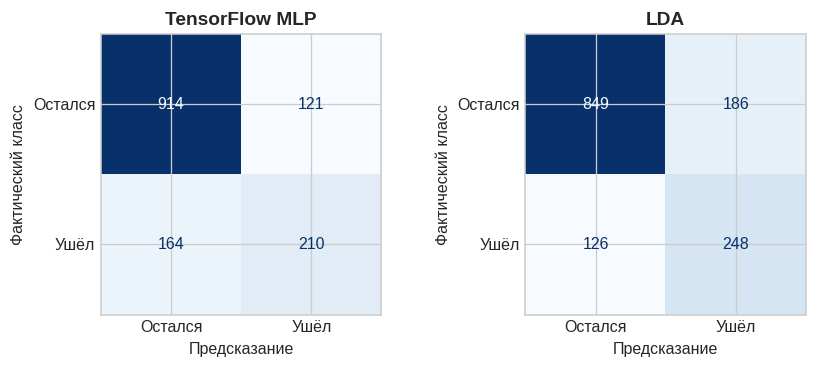

По основному критерию на тесте лидирует **TensorFlow MLP** с ROC-AUC **0,8441**. Следующий результат у **LDA**, разница составляет 0,0094. При стандартном пороге лидер нашёл 210 ушедших клиентов, пропустил 164 и выдал 121 ложных сигналов. Максимальный F1 у **LDA** (0,6139).

**TensorFlow MLP** получила ROC-AUC 0,8441 и F1 0,5957. Точность **Dummy** составила 0,7346 при нулевом Recall. Это показывает, почему сравнение по одной Accuracy недостаточно для обнаружения оттока.

In [19]:
auc_leader = comparison["ROC-AUC"].idxmax()
f1_leader = comparison["F1"].idxmax()
ranked = comparison.index.tolist()
runner = ranked[1]
confusion_models = list(dict.fromkeys([auc_leader, f1_leader, nn_name]))
fig, axes = plt.subplots(1, len(confusion_models), figsize=(3.8 * len(confusion_models), 3.3), squeeze=False)
for ax, name in zip(axes.ravel(), confusion_models):
    matrix = confusion_matrix(y_test, predictions[name], labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["Остался", "Ушёл"]).plot(
        ax=ax, colorbar=False, cmap="Blues",
    )
    ax.set(title=name, xlabel="Предсказание", ylabel="Фактический класс")
fig.tight_layout()
plt.show()

_, n_false_alert, n_missed, n_found = confusion_matrix(
    y_test, predictions[auc_leader], labels=[0, 1],
).ravel()
test_gap = comparison.loc[auc_leader, "ROC-AUC"] - comparison.loc[runner, "ROC-AUC"]
display(Markdown(
    f"По основному критерию на тесте лидирует **{auc_leader}** с ROC-AUC "
    f"**{fmt(comparison.loc[auc_leader, 'ROC-AUC'])}**. "
    f"Следующий результат у **{runner}**, разница составляет {fmt(test_gap)}. "
    f"При стандартном пороге лидер нашёл {n_found} ушедших клиентов, пропустил {n_missed} "
    f"и выдал {n_false_alert} ложных сигналов. "
    f"Максимальный F1 у **{f1_leader}** ({fmt(comparison.loc[f1_leader, 'F1'])}).\n\n"
    f"**TensorFlow MLP** получила ROC-AUC {fmt(comparison.loc[nn_name, 'ROC-AUC'])} "
    f"и F1 {fmt(comparison.loc[nn_name, 'F1'])}. "
    f"Точность **Dummy** составила {fmt(comparison.loc['Dummy', 'Accuracy'])} при нулевом Recall. "
    "Это показывает, почему сравнение по одной Accuracy недостаточно для обнаружения оттока."
))

## 8. Заключение

In [20]:
display(Markdown(
    f"На датасете Telco Customer Churn обучены восемь классических классификаторов "
    f"и многослойная нейросеть. Перебрано {len(cv_trials)} комбинаций гиперпараметров "
    f"классических моделей и проведено {len(nn_configs)} запусков TensorFlow с журналами TensorBoard. "
    f"В пределах проведённого эксперимента **{auc_leader}** — лучший из проверенных подходов "
    f"для ранжирования клиентов по риску оттока. "
    f"Если важен баланс Precision и Recall при использованном пороге, "
    f"ориентиром служит **{f1_leader}**, показавший наибольший F1.\n\n"
    "Оценки получены на одном отложенном тесте. Стабильность различий между близкими моделями "
    "и чувствительность нейросети к случайной инициализации отдельно не проверялись."
))

На датасете Telco Customer Churn обучены восемь классических классификаторов и многослойная нейросеть. Перебрано 100 комбинаций гиперпараметров классических моделей и проведено 11 запусков TensorFlow с журналами TensorBoard. В пределах проведённого эксперимента **TensorFlow MLP** — лучший из проверенных подходов для ранжирования клиентов по риску оттока. Если важен баланс Precision и Recall при использованном пороге, ориентиром служит **LDA**, показавший наибольший F1.

Оценки получены на одном отложенном тесте. Стабильность различий между близкими моделями и чувствительность нейросети к случайной инициализации отдельно не проверялись.

### Источники

- [Telco Customer Churn — описание и CSV на Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
- [Scikit-Learn — официальное руководство по классификаторам](https://scikit-learn.org/1.8/supervised_learning.html)
- [TensorFlow — callback TensorBoard](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/TensorBoard)